# 04 - BERTopic

**Objetivo:** encontrar los tópicos de los tweets con BERTopic, ver cuáles reflejan **eventos** de abril–junio de 2009 y **validarlos con fuentes**.

Qué responde:
1. ¿Cómo funciona BERTopic y qué hace cada componente?
2. ¿Qué tamaño mínimo de tópico conviene? (métricas)
3. ¿De qué hablan los tweets?
4. ¿Qué tópicos tienen un pico en el tiempo, y coinciden con eventos reales?
5. ¿Qué pasa con los tweets que no entran en ningún tópico (outliers)?

#### Dependencias

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from bertopic import BERTopic
from bertopic.representation import KeyBERTInspired
from bertopic.vectorizers import ClassTfidfTransformer
from hdbscan import HDBSCAN
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

import utils
from eventos import EVENTOS

warnings.filterwarnings("ignore", category=FutureWarning)

#### Parámetros

In [2]:
RANDOM_STATE = 42
HILOS = 8

# UMAP: 5 dimensiones para agrupar, 2 para graficar
UMAP_PARAMS = dict(n_neighbors=15, min_dist=0.0, metric="cosine", random_state=RANDOM_STATE)

# HDBSCAN: se comparan tres tamaños mínimos de tópico
MIN_CLUSTER_SIZES = [50, 100, 200]
MIN_SAMPLES = 10        # menor = menos outliers; fijo para comparar solo min_cluster_size

# Vectorizador de c-TF-IDF
MIN_DF = 10             # términos en al menos 10 tweets
TOP_PALABRAS = 10       # palabras por tópico para las métricas

FILE_UMAP_5D = utils.PROCESSED_DIR / "umap_5d.npy"
FILE_UMAP_2D = utils.PROCESSED_DIR / "umap_2d.npy"
DIR_MODELO = utils.MODELS_DIR / "bertopic"
FILE_TOPICOS = utils.PROCESSED_DIR / "topicos_bertopic.csv"

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
torch.set_num_threads(HILOS)

#### Funciones

In [3]:
def umap_guardado(path, n_componentes, min_dist):
    """Reducción UMAP de los embeddings, calculada una vez y guardada."""
    if path.exists():
        return np.load(path)
    inicio = time.time()
    params = UMAP_PARAMS | {"n_components": n_componentes, "min_dist": min_dist}
    reducidos = UMAP(**params).fit_transform(emb)
    print(f"UMAP {n_componentes}D: {(time.time() - inicio) / 60:.1f} min")
    np.save(path, reducidos)
    return reducidos


def palabras_topicos(modelo, n=TOP_PALABRAS):
    """Top-n palabras (c-TF-IDF) de cada tópico, sin el -1."""
    ids = [t for t in modelo.get_topics() if t != -1]
    return ids, [[w for w, _ in modelo.get_topic(t)[:n]] for t in ids]


def etiqueta(modelo, t, n=4):
    return f"{t}: " + ", ".join(w for w, _ in modelo.get_topic(t)[:n])

## 1. Cómo funciona BERTopic

BERTopic arma tópicos en cinco pasos, más uno opcional. Cada uno es un componente que se puede cambiar:

| Paso | Componente | Qué hace | Por qué hace falta | En este TP |
| --- | --- | --- | --- | --- |
| 1 | **Embeddings** (`all-MiniLM-L6-v2`) | Convierte cada tweet en un vector de 384 números según su significado | Tweets con palabras distintas pero el mismo tema (`RIP Farrah` «QEPD Farrah» / `so sad about Farrah` «qué triste lo de Farrah») quedan cerca | Calculados en la 03 |
| 2 | **UMAP** | Reduce los 384 números a 5, conservando quién está cerca de quién | En muchas dimensiones todas las distancias se parecen y el agrupamiento por densidad no funciona | 15 vecinos, distancia coseno, semilla fija |
| 3 | **HDBSCAN** | Agrupa por densidad: un tópico es una zona con muchos tweets juntos. No hay que fijar la cantidad de tópicos. Los tweets en zonas poco densas quedan como **outliers (-1)** | La mayoría de los tweets es charla suelta: es mejor dejarla afuera que forzarla en un tópico | `min_cluster_size` se elige en la sección 3 |
| 4 | **CountVectorizer** | Cuenta las palabras de los tweets de cada tópico | Paso previo a describir los tópicos con palabras | Stopwords, unigramas y bigramas, `min_df=10` |
| 5 | **c-TF-IDF** | TF-IDF por clase: junta los tweets de un tópico como si fueran un solo documento y busca palabras **frecuentes en el tópico y raras en el resto** | Da las palabras que describen a cada tópico | `reduce_frequent_words=True` |
| 6 (opcional) | **Representación** (`KeyBERTInspired`) | Reordena las palabras candidatas de c-TF-IDF según su **similitud coseno** con el tópico: el criterio de KeyBERT, aplicado a un tópico entero | c-TF-IDF premia palabras exclusivas del tópico, aunque sean raras; esto premia las que mejor resumen su significado | Aspecto adicional `KeyBERT` (sección 3) |

- Los pasos 1–3 deciden **qué tweets van juntos** (usan el significado). Los pasos 4–5 solo deciden **cómo se describe** cada tópico (usan las palabras).
- UMAP es el paso más lento. Se calcula una vez, se guarda y se le pasa a BERTopic con `utils.ReduccionGuardada`. Así se comparan varios HDBSCAN sobre la misma reducción.

## 2. Datos y reducción UMAP

In [4]:
muestra = utils.cargar_muestra()
emb = utils.cargar_embeddings(len(muestra))
docs = muestra["texto_limpio"].tolist()
textos = muestra["texto_limpio"].str.lower()      # para buscar eventos con regex

reducidos_5d = umap_guardado(FILE_UMAP_5D, 5, min_dist=0.0)
reducidos_2d = umap_guardado(FILE_UMAP_2D, 2, min_dist=0.1)
print(f"{len(docs):,} tweets | UMAP 5D {reducidos_5d.shape} | UMAP 2D {reducidos_2d.shape}")

217,133 tweets | UMAP 5D (217133, 5) | UMAP 2D (217133, 2)


## 3. Elección del tamaño mínimo de tópico

`min_cluster_size` es el parámetro principal de HDBSCAN: la menor cantidad de tweets que puede tener un tópico. Se prueban 50, 100 y 200, con todo lo demás fijo.

Métricas:

| Métrica | Qué mide | Mejor |
| --- | --- | --- |
| % outliers | Tweets que no entran en ningún tópico | Menor (pero no a costa de tópicos forzados) |
| **Coherencia NPMI** | Si las palabras de un tópico aparecen **juntas en los mismos tweets**. Es la PMI normalizada entre -1 (nunca juntas) y 1 (siempre juntas) | Mayor |
| **Coherencia por embeddings** | Similitud coseno promedio entre los embeddings de las palabras de un tópico: si son **semánticamente parecidas** | Mayor |
| Diversidad | Proporción de palabras distintas entre los top-10 de todos los tópicos (1 = ninguna se repite) | Mayor |
| Eventos aislados | Hipótesis de la 02 (28 eventos) cuyo tópico tiene precisión ≥ 50%: la mitad o más de sus tweets mencionan el evento | Mayor |

In [5]:
# Solo las hipótesis de la 02: los eventos nuevos los encontró el propio modelo con 50
EVENTOS_EDA = {k: v for k, v in EVENTOS.items() if v["origen"] == "EDA"}

modelo_emb = SentenceTransformer(utils.MODELO_EMBEDDINGS, device="cpu")
vectorizador = CountVectorizer(stop_words=utils.STOPWORDS, token_pattern=utils.TOKEN_PATTERN,
                               ngram_range=(1, 2), min_df=MIN_DF)

# matriz binaria tweets x términos para la NPMI (mismo vocabulario que c-TF-IDF)
X_bin = vectorizador.fit_transform(docs)
X_bin.data[:] = 1
X_bin = X_bin.tocsc()
vocab = vectorizador.get_feature_names_out()

modelos, filas = {}, []
for mcs in MIN_CLUSTER_SIZES:
    inicio = time.time()
    modelo = BERTopic(
        embedding_model=modelo_emb,
        umap_model=utils.ReduccionGuardada(reducidos_5d),
        hdbscan_model=HDBSCAN(min_cluster_size=mcs, min_samples=MIN_SAMPLES),
        vectorizer_model=vectorizador,
        ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
    )
    topicos, _ = modelo.fit_transform(docs, embeddings=emb)
    topicos = np.array(topicos)
    ids, palabras = palabras_topicos(modelo)
    eventos_ev = utils.evaluar_eventos(topicos, textos, muestra["dia"], EVENTOS_EDA)
    modelos[mcs] = (modelo, topicos)
    filas.append({
        "min_cluster_size": mcs,
        "tópicos": len(ids),
        "% outliers": (topicos == -1).mean() * 100,
        "NPMI": np.nanmean(utils.coherencia_npmi(palabras, X_bin, vocab)),
        "coherencia embeddings": np.nanmean(utils.coherencia_embeddings(palabras, modelo_emb)),
        "diversidad": utils.diversidad(palabras),
        "eventos aislados": int(eventos_ev["aislado"].sum()),
        "segundos": time.time() - inicio,
    })

comparacion = pd.DataFrame(filas).set_index("min_cluster_size").round(3)
comparacion

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,tópicos,% outliers,NPMI,coherencia embeddings,diversidad,eventos aislados,segundos
min_cluster_size,,,,,,,
50,549,43.269,-0.597,0.332,0.732,17,30.286
100,327,45.232,-0.473,0.373,0.810,13,24.923
200,188,44.269,-0.359,0.414,0.869,5,23.245


In [6]:
# Por qué la NPMI da negativa: muchos pares de palabras top nunca aparecen en el mismo tweet
_, palabras_50 = palabras_topicos(modelos[50][0])
indice = {w: i for i, w in enumerate(vocab)}
pares, sin_coocurrencia = 0, 0
for t in palabras_50:
    sub = X_bin[:, [indice[w] for w in t if w in indice]]
    co = (sub.T @ sub).toarray()
    arriba = co[np.triu_indices(len(co), 1)]
    pares += len(arriba)
    sin_coocurrencia += (arriba == 0).sum()
print(f"Pares de palabras top que nunca aparecen en un mismo tweet: {sin_coocurrencia / pares:.0%}")
print("Ejemplo de tópico:", palabras_50[0][:6])

Pares de palabras top que nunca aparecen en un mismo tweet: 68%
Ejemplo de tópico: ['tweets', 'tweeting', 'twittering', 'tweet', 'twitters', 'tweeted']


- **Más chico el tamaño mínimo → más tópicos**, menos coherentes y menos diversos, pero **más eventos aislados**. Un evento con menos tweets que `min_cluster_size` no puede formar un tópico propio. Farrah Fawcett tiene 160 tweets en la muestra: con 200 queda repartida entre outliers y otros tópicos.
- La **NPMI es negativa** en las tres configuraciones. Los tweets tienen 12 palabras y los tópicos suelen agrupar variantes de una palabra (`tweet`, `tweets`, `tweeting`) que casi nunca aparecen juntas en un mismo tweet: cada par que no coincide cuenta -1. Sirve para **comparar** configuraciones, no como valor absoluto.
- La **coherencia por embeddings** sí reconoce esas variantes como parecidas: es positiva y sube con el tamaño mínimo (0,33 → 0,41), igual que la NPMI. Tópicos más grandes son más generales y sus palabras, más parecidas entre sí.
- El % de outliers casi no cambia (~43–45%): depende más de `min_samples` y de cuánta charla suelta hay.
- **Se elige `min_cluster_size=50`.** El objetivo es encontrar eventos, y es la configuración que más aísla (17 de los 28 candidatos de la 02). El costo es tener más tópicos, pero los de eventos se ubican fácil con su pico en el tiempo (sección 5).

In [7]:
MCS_FINAL = 50
modelo, topicos = modelos[MCS_FINAL]
info = modelo.get_topic_info()
print(f"{len(info) - 1} tópicos | {(topicos == -1).mean():.1%} outliers")

549 tópicos | 43.3% outliers


**Palabras clave por tópico (componente 6).** Al modelo elegido se le agrega una segunda representación con `KeyBERTInspired`: toma las 100 palabras candidatas de c-TF-IDF de cada tópico, arma el embedding del tópico con sus tweets más representativos y se queda con las palabras más parecidas por similitud coseno. Se guarda como el aspecto `KeyBERT`; las palabras principales (c-TF-IDF) no cambian.

In [ ]:
antes = {t: [w for w, _ in modelo.get_topic(t)] for t in modelo.get_topics()}
modelo.update_topics(docs, topics=topicos, vectorizer_model=vectorizador,
                     ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
                     representation_model={"KeyBERT": KeyBERTInspired(random_state=RANDOM_STATE)})
despues = {t: [w for w, _ in modelo.get_topic(t)] for t in modelo.get_topics()}
print("Palabras c-TF-IDF sin cambios:", antes == despues)
print("Aspectos disponibles:", list(modelo.topic_aspects_))


def palabras_keybert(t, n=5):
    return [w for w, _ in modelo.topic_aspects_["KeyBERT"][t][:n]]

## 4. De qué hablan los tweets

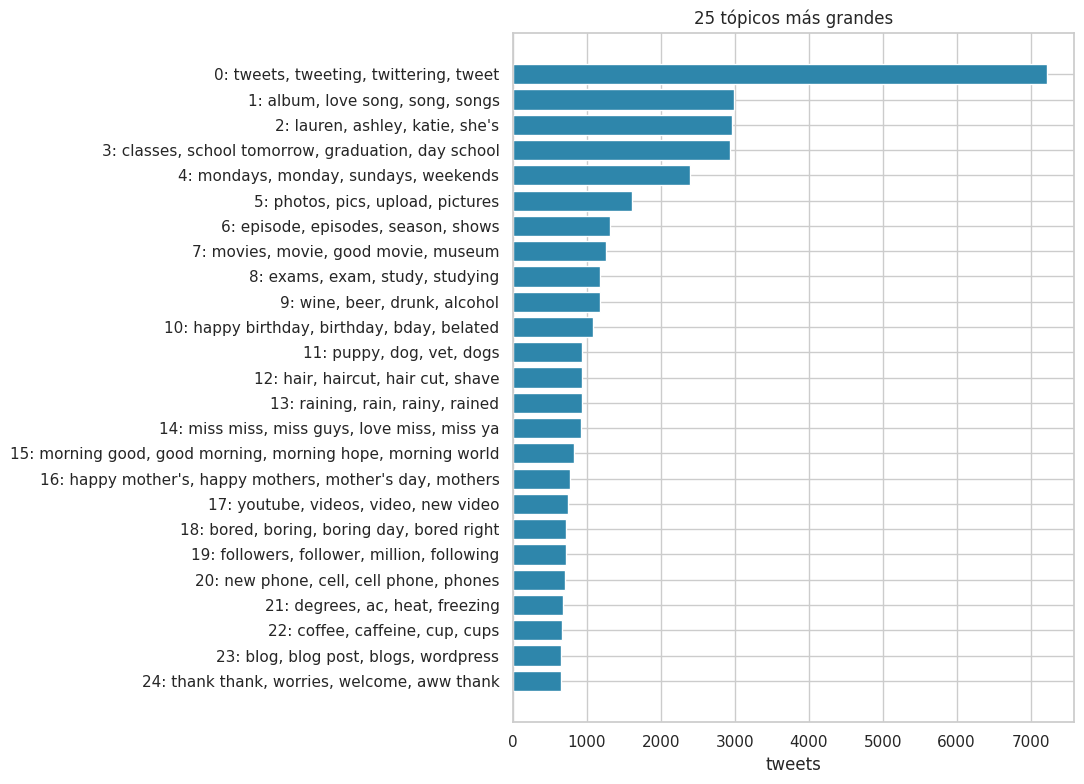

In [8]:
top = info[info["Topic"] != -1].head(25)
fig, ax = plt.subplots(figsize=(11, 8))
ax.barh([etiqueta(modelo, t) for t in top["Topic"]][::-1], top["Count"][::-1], color="#2e86ab")
ax.set(title="25 tópicos más grandes", xlabel="tweets")
plt.tight_layout()
plt.show()

- Los tópicos más grandes son **la vida diaria**: Twitter mismo, colegio y exámenes, días de la semana, fotos, alcohol, sueño, series de TV, cumpleaños, salud, mascotas, clima.
- Coincide con el EDA y con cómo se armó el dataset: se buscaron tweets con emoticones, y eso trae sobre todo charla personal.

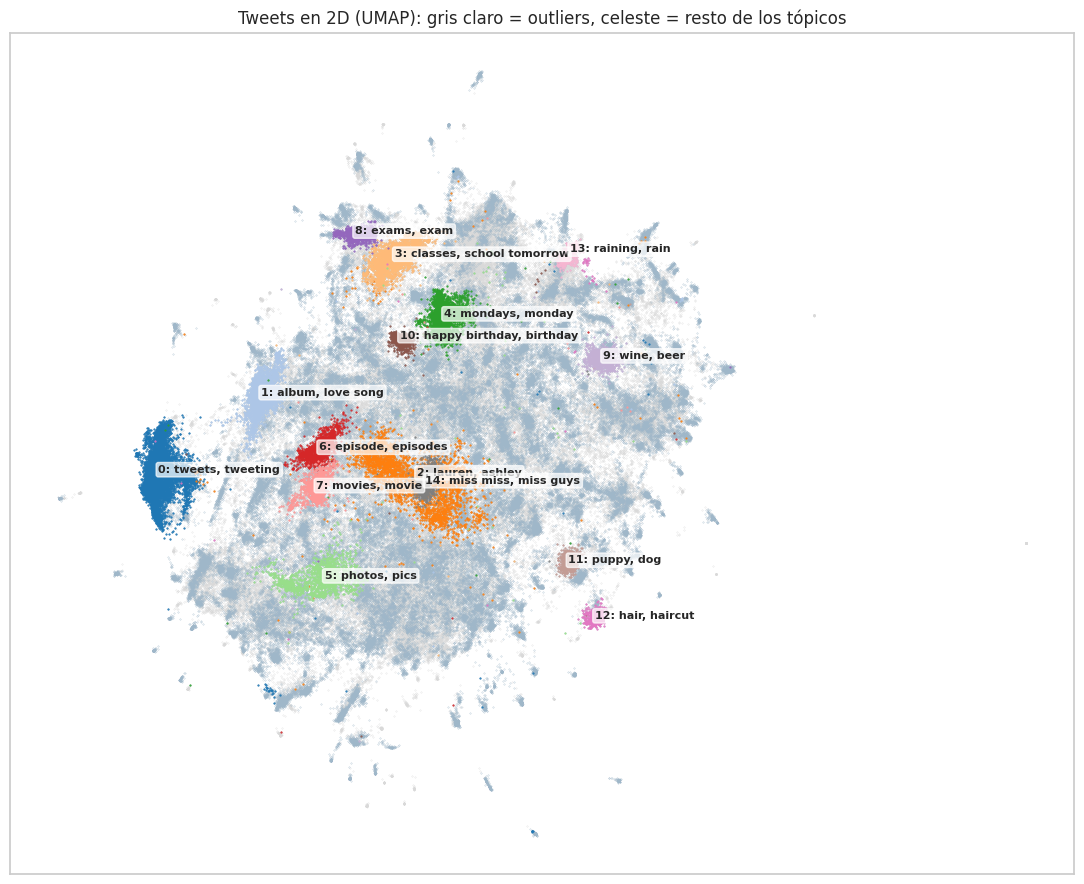

In [9]:
# Mapa 2D: cada punto es un tweet. Gris = outliers; colores = los 15 tópicos más grandes
fig, ax = plt.subplots(figsize=(11, 9))
es_out = topicos == -1
ax.scatter(*reducidos_2d[es_out].T, s=0.05, c="#d9d9d9", rasterized=True)
ax.scatter(*reducidos_2d[~es_out].T, s=0.05, c="#9fb7c9", rasterized=True)
paleta = sns.color_palette("tab20", 15)
for color, t in zip(paleta, top["Topic"][:15]):
    puntos = reducidos_2d[topicos == t]
    ax.scatter(*puntos.T, s=0.3, color=color, rasterized=True)
    ax.annotate(etiqueta(modelo, t, 2), np.median(puntos, axis=0), fontsize=8, weight="bold",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7))
ax.set(title="Tweets en 2D (UMAP): gris claro = outliers, celeste = resto de los tópicos", xticks=[], yticks=[])
plt.tight_layout()
plt.show()

- Los tópicos grandes son **islas densas**: tweets muy parecidos entre sí (saludos, cumpleaños, Día de la Madre).
- Los outliers (gris claro) ocupan el resto del mapa: tweets sueltos que no comparten tema con suficientes otros.

## 5. Tópicos en el tiempo

Se usa la misma idea que en la 02, ahora con tópicos en lugar de palabras:

$$\text{PMI}(\text{tópico}, \text{día}) = \log_2 \frac{P(\text{tópico} \mid \text{día})}{P(\text{tópico})}$$

- Mide cuántas veces más aparece un tópico ese día que en todo el período. Usa **proporciones**, así que no le afecta el volumen de cada día.
- Se exige que el tópico tenga al menos 20 tweets ese día.
- **Concentración** = % de los tweets del tópico que caen en sus 2 días principales. Un evento puntual tiene concentración alta; un tema cotidiano, baja.

In [10]:
pmi, conteo = utils.pmi_grupo_dia(topicos, muestra["dia"], min_tweets=20)
temporal = pd.DataFrame({
    "tweets": conteo.sum(axis=1),
    "PMI máx": pmi.max(axis=1).round(2),
    "día del pico": pmi.idxmax(axis=1).dt.strftime("%d/%m"),
    "concentración 2 días": conteo.apply(lambda r: r.nlargest(2).sum() / r.sum(), axis=1).round(2),
    "palabras": [", ".join(w for w, _ in modelo.get_topic(t)[:5]) for t in conteo.index],
}).sort_values("PMI máx", ascending=False)

print(f"Tópicos con PMI máx >= 3 (8 veces más que su promedio): {(temporal['PMI máx'] >= 3).sum()}")
temporal.head(35)

Tópicos con PMI máx >= 3 (8 veces más que su promedio): 33


,tweets,PMI máx,día del pico,concentración 2 días,palabras
grupo,,,,,
213,163,5.26,25/06,0.93,"passed away, rest peace, rip, cancer, passed"
435,69,5.07,22/06,0.90,"metro, dc, crash, wreck, prayers"
356,91,4.84,04/05,0.76,"bank holiday, bank, holiday, holidays, fitting"
179,186,4.83,04/06,0.70,"david, gary, fu, rip, papa"
341,95,4.69,04/05,0.66,"wars, fourth, star, day happy, force"
489,57,4.63,30/05,0.74,"bgt, diversity, act, love soo, better make"
300,112,4.61,31/05,0.65,"mtv, mtv movie, movie awards, awards, ready watch"
449,67,4.52,13/05,0.52,"allison, jake, model, robbed, win"
278,120,4.49,23/06,0.57,"ed, raw, rip, monday night, passed away"


- Los tópicos con PMI más alta son casi todos **eventos puntuales**: muertes de famosos, finales de programas de TV, estrenos, lanzamientos, fechas especiales y noticias.
- También aparecen tópicos que **no estaban en las hipótesis** de la 02. Se validan con fuentes igual que el resto: el choque del metro de Washington (22/6), el estreno de la temporada 2 de *True Blood* (14/6), el GP británico de F1 (21/6), el feriado bancario de mayo en el Reino Unido y el Día de Star Wars (4/5), y la final de *America's Next Top Model* (13/5).
- Algunos tópicos con pico no son eventos externos (por ejemplo `followfriday`, una costumbre de Twitter de los viernes).

## 6. Validación con fuentes

Para cada evento candidato (los 28 de la 02 y los 6 nuevos que encontró BERTopic):

- **Tópico:** el que reúne más tweets que mencionan el evento (búsqueda por palabras clave).
- **Precisión:** % de los tweets del tópico que mencionan el evento. Es una cota inferior: muchos tweets hablan del evento sin nombrarlo (*"RIP Ed"*, «QEPD Ed», en vez de *"Ed McMahon"*).
- **Recall:** % de los tweets que mencionan el evento que caen en ese tópico.
- **Pico ok:** el día de máxima PMI del tópico coincide con la fecha de la fuente (±1 día, o el primer día con datos si la fecha cae en un hueco).
- **Confirmado** = tópico propio (precisión ≥ 50%) **y** pico ok. Las fechas y los links están en `eventos.py`.

In [11]:
validacion = utils.evaluar_eventos(topicos, textos, muestra["dia"], EVENTOS)
validacion["palabras del tópico"] = [
    ", ".join(w for w, _ in modelo.get_topic(int(g))[:4]) if pd.notna(g) else "" for g in validacion["grupo"]]
print(f"Confirmados: {validacion['confirmado'].sum()} de {len(validacion)}")
validacion.drop(columns=["aislado"]).rename(columns={"grupo": "tópico"})

Confirmados: 22 de 34


,evento,origen,tweets,tópico,precisión,recall,pico del grupo,fecha fuente,pico ok,confirmado,palabras del tópico
0,Pascua,EDA,102,413,0.16,0.12,07/04,12/04,False,False,"eggs, egg, easter, fried"
1,Oracle anuncia la compra de Sun,EDA,36,357,0.01,0.03,14/05,20/04,False,False,"ellen, holly, paris, died sad"
2,Gripe porcina: la OMS sube la alerta a fase 4 y 5,EDA,236,115,0.80,0.86,01/05,27/04 y 29/04,True,True,"swine, flu, cases, confirmed"
3,Estreno de X-Men Origins: Wolverine,EDA,137,164,0.66,0.95,01/05,01/05,True,True,"men, hugh, great good, watching new"
4,Pelea Pacquiao–Hatton,EDA,29,34,0.00,0.03,02/06,02/05,False,False,"gym, workout, fitness, exercise"
5,Estreno de Star Trek,EDA,294,86,0.82,0.87,09/05,08/05,True,True,"star trek, trek, star, pine"
6,Día de la Madre (EE. UU.),EDA,780,16,0.68,0.67,10/05,10/05,True,True,"happy mother's, happy mothers, mother's day, mothers"
7,Danny Gokey eliminado de American Idol,EDA,228,215,0.26,0.18,13/05,13/05,True,False,"danny, american idol, idol, sent home"
8,Final de Eurovisión,EDA,38,370,0.01,0.03,17/06,16/05,False,False,"itunes, downloading, downloads, songs"
9,Lanzamiento de Wolfram Alpha,EDA,18,63,0.01,0.11,18/05,15/05 y 18/05,True,False,"math, maths, exam, exam tomorrow"


**Fuentes** (fechas verificadas en noviembre de 2026):

| Evento | Origen | Fecha | Fuente |
| --- | --- | --- | --- |
| Pascua | EDA | 12/04 | Cálculo con `dateutil.easter`; [Wikipedia](https://en.wikipedia.org/wiki/Easter) |
| Oracle anuncia la compra de Sun | EDA | 20/04 | [Wikipedia](https://en.wikipedia.org/wiki/Acquisition_of_Sun_Microsystems_by_Oracle_Corporation) |
| Gripe porcina: la OMS sube la alerta a fase 4 y 5 | EDA | 27/04, 29/04 | [Wikipedia](https://en.wikipedia.org/wiki/2009_swine_flu_pandemic_timeline) |
| Estreno de X-Men Origins: Wolverine | EDA | 01/05 | [Wikipedia](https://en.wikipedia.org/wiki/X-Men_Origins:_Wolverine) |
| Pelea Pacquiao–Hatton | EDA | 02/05 | [Wikipedia](https://en.wikipedia.org/wiki/Manny_Pacquiao_vs._Ricky_Hatton), [BBC](https://news.bbc.co.uk/sport2/hi/boxing/8028250.stm) |
| Estreno de Star Trek | EDA | 08/05 | [Wikipedia](https://en.wikipedia.org/wiki/Star_Trek_(2009_film)) |
| Día de la Madre (EE. UU.) | EDA | 10/05 | Segundo domingo de mayo: [Wikipedia](https://en.wikipedia.org/wiki/Mother%27s_Day_(United_States)) |
| Danny Gokey eliminado de American Idol | EDA | 13/05 | [Wikipedia](https://en.wikipedia.org/wiki/Danny_Gokey) |
| Final de Eurovisión | EDA | 16/05 | [Wikipedia](https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2009) |
| Lanzamiento de Wolfram Alpha | EDA | 15/05, 18/05 | [Wikipedia](https://en.wikipedia.org/wiki/WolframAlpha), [BBC](https://news.bbc.co.uk/1/hi/technology/8052798.stm) |
| Final de Britain's Got Talent | EDA | 30/05 | [Wikipedia](https://en.wikipedia.org/wiki/Britain%27s_Got_Talent_series_3) |
| MTV Movie Awards | EDA | 31/05 | [Wikipedia](https://en.wikipedia.org/wiki/2009_MTV_Movie_Awards), [Variety](https://variety.com/2009/film/awards/twilight-tops-mtv-movie-awards-1118004362/) |
| Adelanto de New Moon (en los MTV Movie Awards) | EDA | 31/05 | [Wikipedia](https://en.wikipedia.org/wiki/2009_MTV_Movie_Awards) |
| Último Tonight Show de Leno / debut de Conan | EDA | 29/05, 01/06 | [Wikipedia](https://en.wikipedia.org/wiki/The_Tonight_Show_with_Conan_O%27Brien) |
| Air France 447 cae en el Atlántico | EDA | 01/06 | [Wikipedia](https://en.wikipedia.org/wiki/Air_France_Flight_447) |
| E3 y Project Natal | EDA | 01/06, 02/06 | [E3 2009](https://en.wikipedia.org/wiki/E3_2009), [Kinect](https://en.wikipedia.org/wiki/Kinect) |
| Muerte de David Carradine | EDA | 03/06, 04/06 | [Wikipedia](https://en.wikipedia.org/wiki/David_Carradine), [BBC](http://news.bbc.co.uk/1/hi/entertainment/8083479.stm) |
| Lanzamiento de Los Sims 3 | EDA | 02/06 | [Wikipedia](https://en.wikipedia.org/wiki/The_Sims_3) |
| Lanzamiento del Palm Pre | EDA | 06/06 | [Wikipedia](https://en.wikipedia.org/wiki/Palm_Pre) |
| Elecciones europeas (el BNP gana sus primeras bancas) | EDA | 04/06, 07/06 | [Wikipedia](https://en.wikipedia.org/wiki/2009_European_Parliament_election_in_the_United_Kingdom), [BBC](https://news.bbc.co.uk/2/hi/europe/8088309.stm) |
| Lakers campeones de la NBA | EDA | 14/06 | [Wikipedia](https://en.wikipedia.org/wiki/2009_NBA_Finals) |
| Elecciones y protestas en Irán; muerte de Neda | EDA | 12/06, 20/06 | [Protestas](https://en.wikipedia.org/wiki/2009_Iranian_presidential_election_protests), [Neda](https://en.wikipedia.org/wiki/Killing_of_Neda_Agha-Soltan) |
| iPhone OS 3.0 y iPhone 3GS | EDA | 17/06, 19/06 | [iPhone OS 3](https://en.wikipedia.org/wiki/IPhone_OS_3), [iPhone 3GS](https://en.wikipedia.org/wiki/IPhone_3GS) |
| Día del Padre (EE. UU.) | EDA | 21/06 | Tercer domingo de junio: [Wikipedia](https://en.wikipedia.org/wiki/Father%27s_Day) |
| Jon y Kate Gosselin anuncian su separación | EDA | 22/06 | [Wikipedia](https://en.wikipedia.org/wiki/List_of_Kate_Plus_8_episodes) |
| Muerte de Ed McMahon | EDA | 23/06 | [Wikipedia](https://en.wikipedia.org/wiki/Ed_McMahon), [CTV](https://www.ctvnews.ca/legendary-tv-host-ed-mcmahon-dead-at-86-1.410459) |
| Estreno de Transformers 2 | EDA | 24/06 | [Wikipedia](https://en.wikipedia.org/wiki/Transformers:_Revenge_of_the_Fallen) |
| Muerte de Farrah Fawcett (9:28 PDT) | EDA | 25/06 | [Wikipedia](https://en.wikipedia.org/wiki/Farrah_Fawcett), [People](https://people.com/celebrity/farrah-fawcett-dies-of-cancer-at-62/) |
| Día de Star Wars (4 de mayo) | BERTopic | 04/05 | [Wikipedia](https://en.wikipedia.org/wiki/Star_Wars_Day) |
| Feriado bancario de mayo (Reino Unido) | BERTopic | 04/05 | Primer lunes de mayo: [Wikipedia](https://en.wikipedia.org/wiki/Public_holidays_in_the_United_Kingdom) |
| Final de America's Next Top Model (Allison Harvard 2.ª) | BERTopic | 13/05 | [Wikipedia](https://en.wikipedia.org/wiki/America%27s_Next_Top_Model_season_12) |
| Estreno de la temporada 2 de True Blood | BERTopic | 14/06 | [Wikipedia](https://en.wikipedia.org/wiki/True_Blood_season_2) |
| GP británico de Fórmula 1 (gana Vettel) | BERTopic | 21/06 | [Wikipedia](https://en.wikipedia.org/wiki/2009_British_Grand_Prix), [BBC](https://news.bbc.co.uk/sport1/hi/motorsport/formula_one/8111672.stm) |
| Choque de trenes del metro de Washington (9 muertos) | BERTopic | 22/06 | [Wikipedia](https://en.wikipedia.org/wiki/June_2009_Washington_Metro_train_collision) |

- **22 de 34 eventos quedan confirmados**: el modelo les dio un tópico propio y el pico coincide con la fecha de la fuente.
- Los no confirmados se explican por:
  - **Pocos tweets en la muestra** (menos que `min_cluster_size=50`): Oracle–Sun (36), Eurovisión (38), Pacquiao–Hatton (29), Wolfram Alpha (18), Palm Pre (18), elecciones europeas (28). Quedan como outliers o mezclados en tópicos generales (`vote, voted, voting`).
  - **Precisión apenas debajo del 50%** con el pico correcto: Ed McMahon (0,49), iPhone OS 3 (0,47) y Día del Padre (0,45). Los tópicos tratan del evento, pero muchos tweets no usan las palabras buscadas (*"RIP Ed"*, «QEPD Ed»; *"happy dad's day"*, «feliz día, papá»).
  - **Evento repartido en varios tópicos**: *American Idol* se divide en un tópico por participante (`danny`, `adam / kris`, `archuleta`), todos con pico el 13/5. *Top Model* (0,30) comparte tópico con otros programas de esa noche.
  - **Pascua:** cae el 12/4, en un hueco del dataset (8–16/4). Solo queda un tópico de huevos y conejos sin pico en la fecha.

**Ejemplo de validación fina: Farrah Fawcett murió a las 9:28 PDT del 25/6** (fuente: Wikipedia, People).

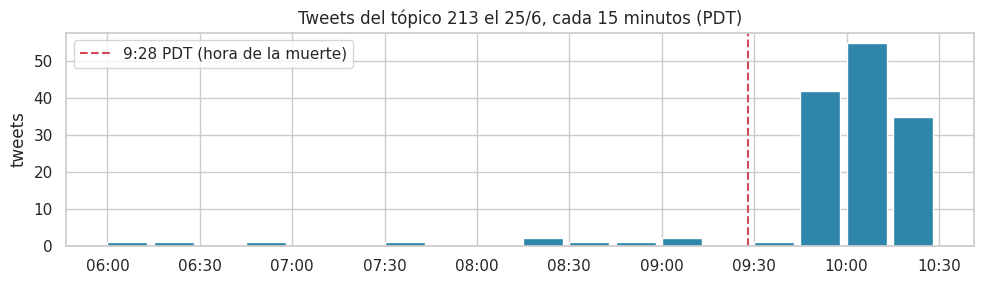

,fecha_pdt,texto_limpio,traducción
214770,2009-06-25 06:03:34,- soo cute .. RIP Rosh ..,- Re tierno... QEPD Rosh...
214957,2009-06-25 06:24:37,Sat prayers for Farrah Fawcett she is in critical condition in hospital w/ family at her bedside & was given her las...,"Recé por Farrah Fawcett: está en estado crítico en el hospital, con su familia al lado, y le dieron la extremaunción."
215184,2009-06-25 06:51:46,Farah Fawcett given last right,A Farrah Fawcett le dieron la extremaunción.
215558,2009-06-25 07:34:59,My prayers and thoughts go out to Farrah Fawcett and her family!,¡Mis oraciones y pensamientos para Farrah Fawcett y su familia!
215965,2009-06-25 08:18:19,"Oh no, that is terrible. Poor Farrah.","Ay no, qué terrible. Pobre Farrah."
216011,2009-06-25 08:24:08,I think they should let Redmond out of prison so he can spend time with Farrah I love Farrah Fawcett,Creo que deberían dejar salir a Redmond de la cárcel para que pase tiempo con Farrah. Amo a Farrah Fawcett.
216174,2009-06-25 08:42:08,Sad news. Farrah Fawcett is not expected to make it through the day,Malas noticias. No se espera que Farrah Fawcett pase el día.
216280,2009-06-25 08:56:12,feeling really bad for Farrah Fawcett,Me siento muy mal por Farrah Fawcett.
216390,2009-06-25 09:08:41,I am on a death watch for Farrah fawcett She was such an big part of my childhood! (in glam tv star way),Estoy pendiente de la muerte de Farrah Fawcett. ¡Fue una parte muy grande de mi infancia! (en plan estrella glamoros...
216428,2009-06-25 09:12:30,I hate that . . . My thoughts and prayers are for Farrah and her family.,Odio eso... Mis pensamientos y oraciones están con Farrah y su familia.


In [12]:
t_farrah = int(validacion.set_index("evento").loc["Muerte de Farrah Fawcett (9:28 PDT)", "grupo"])
dia = muestra[(muestra["dia"] == "2009-06-25") & (topicos == t_farrah)]
cuartos = pd.date_range("2009-06-25 06:00", "2009-06-25 10:15", freq="15min")
por_cuarto = dia["fecha_pdt"].dt.floor("15min").value_counts().reindex(cuartos, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(por_cuarto.index, por_cuarto.values, width=pd.Timedelta(minutes=13), align="edge", color="#2e86ab")
ax.axvline(pd.Timestamp("2009-06-25 09:28"), color="#d1495b", linestyle="--", label="9:28 PDT (hora de la muerte)")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
ax.set(title=f"Tweets del tópico {t_farrah} el 25/6, cada 15 minutos (PDT)", ylabel="tweets")
ax.legend()
plt.tight_layout()
plt.show()

utils.con_traduccion(dia[dia["fecha_pdt"] < "2009-06-25 09:50"].sort_values("fecha_pdt")[["fecha_pdt", "texto_limpio"]],
                     "texto_limpio")

- Antes de las 9:28 hay unos pocos tweets: su estado ya era noticia (*"prayers for Farrah"* («oraciones por Farrah»), *"not expected to make it through the day"* («no se espera que pase el día»)).
- El primer *"Rest in Peace"* («Descanse en paz») aparece a las 9:44 y entre las 9:45 y las 10:00 hay más tweets que en toda la madrugada: el pico en los datos coincide **con la hora** que da la fuente.
- Michael Jackson murió ese mismo día a las 14:26 PDT, después del último tweet del dataset (10:28). En la muestra no tiene tópico ni pico:

In [13]:
mj = textos.str.contains(r"michael jackson|\bmj\b")
print(f"Tweets que mencionan a Michael Jackson: {mj.sum()} ({mj.mean():.2%}); "
      f"el 25/6: {mj[muestra['dia'] == '2009-06-25'].sum()}")

Tweets que mencionan a Michael Jackson: 31 (0.01%); el 25/6: 0


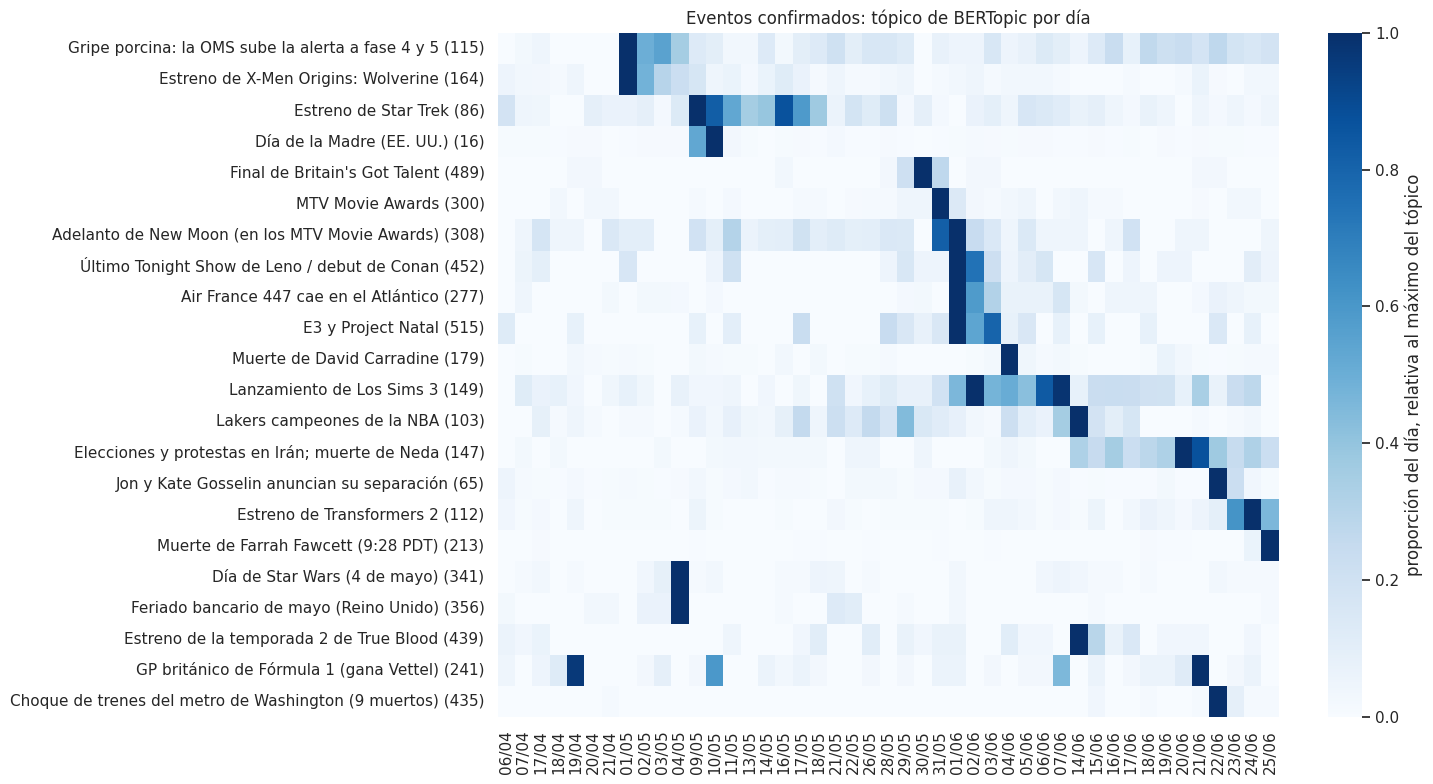

In [14]:
confirmados = validacion[validacion["confirmado"]]
dias_ok = muestra["dia"].value_counts().loc[lambda s: s >= utils.MIN_TWEETS_DIA].index
share = (conteo / conteo.sum(axis=0)).loc[confirmados["grupo"].astype(int), sorted(dias_ok)]
share.index = [f"{e} ({g})" for e, g in zip(confirmados["evento"], confirmados["grupo"])]
share.columns = share.columns.strftime("%d/%m")

fig, ax = plt.subplots(figsize=(15, 8))
sns.heatmap(share.div(share.max(axis=1), axis=0), cmap="Blues", ax=ax,
            cbar_kws={"label": "proporción del día, relativa al máximo del tópico"})
ax.set(title="Eventos confirmados: tópico de BERTopic por día", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

- Igual que en el heatmap de palabras de la 02, aparece **la diagonal**: cada tópico de evento vive uno o dos días.
- La diferencia es que acá **el modelo encontró los grupos solo**, sin que se le dieran las palabras.
- Algunos tópicos son más amplios que el evento. El de F1 cubre la Fórmula 1 en general: también tiene picos el 19/4, el 10/5 y el 7/6, y su máximo es el del GP británico. El de la NBA sube en cada etapa de los playoffs.
- Se omiten los días con menos de 1.000 tweets en la muestra (23, 25 y 27/5).

## 7. Fichas de tópicos

Para presentar los tópicos hace falta más que su lista de palabras. Cada ficha tiene:
- **Nombre puesto a mano.** Para los eventos es la etiqueta de `eventos.py`; para los cotidianos se eligió mirando palabras y ejemplos.
- **Palabras c-TF-IDF** (las que definen el tópico) y **palabras KeyBERT** (las que mejor resumen su significado).
- **Dos tweets de ejemplo:** los más parecidos al centro del tópico por similitud coseno, con al menos 6 palabras.

Se arman para los 6 tópicos más grandes y para los 22 eventos confirmados.

In [ ]:
# Tópicos cotidianos: nombre asociado a su primera palabra c-TF-IDF (no al número)
NOMBRES_COTIDIANOS = {
    "tweets": "Twitter: tuitear", "album": "Música: canciones y álbumes",
    "lauren": "Hablar de amigas («ella», nombres)", "classes": "Escuela y clases",
    "mondays": "Lunes y fin de semana", "photos": "Fotos",
}
etiqueta_evento = {e["nombre"]: e["etiqueta"] for e in EVENTOS.values()}

fichas = [{"tópico": t, "nombre": NOMBRES_COTIDIANOS[modelo.get_topic(t)[0][0]], "tipo": "cotidiano"}
          for t in info.loc[info["Topic"] != -1, "Topic"].head(6)]
fichas += [{"tópico": int(r["grupo"]), "nombre": etiqueta_evento[r["evento"]], "tipo": "evento"}
           for _, r in validacion[validacion["confirmado"]].iterrows()]
fichas = pd.DataFrame(fichas)
fichas["tweets"] = [(topicos == t).sum() for t in fichas["tópico"]]
fichas["palabras c-TF-IDF"] = [", ".join(w for w, _ in modelo.get_topic(t)[:5]) for t in fichas["tópico"]]
fichas["palabras KeyBERT"] = [", ".join(palabras_keybert(t)) for t in fichas["tópico"]]
fichas

**c-TF-IDF vs KeyBERT para nombrar tópicos:**
- **KeyBERT mejora** los tópicos donde c-TF-IDF elige palabras raras o sueltas: Carradine pasa de `david, gary, fu` a `died sad, passed away, actor`; Air France, de `france, plane, air` a `flight, plane, pilot`; *Britain's Got Talent* suma `winners, won`.
- **c-TF-IDF es mejor** cuando la palabra que identifica al evento es rara: el Día de Star Wars se reconoce por `wars, fourth, star`, mientras que KeyBERT lo diluye en `day happy`. Lo mismo con *True Blood*.
- En algunos casos **ninguna sirve** (Conan en *The Tonight Show*, E3): el tópico se entiende recién con los ejemplos.
- Conclusión: las representaciones automáticas se complementan, pero para presentar los tópicos hace falta un **nombre puesto a mano**, apoyado en las palabras y en los ejemplos.

In [ ]:
fig, axes = plt.subplots(7, 4, figsize=(16, 24))
for ax, (_, f) in zip(axes.flat, fichas.iterrows()):
    palabras, puntajes = zip(*modelo.get_topic(f["tópico"])[:6])
    color = "#2e86ab" if f["tipo"] == "evento" else "#8c8c8c"
    ax.barh(palabras[::-1], puntajes[::-1], color=color)
    ax.set_title(f'{f["nombre"]} ({f["tópico"]})', fontsize=10)
    ax.tick_params(axis="both", labelsize=8)
for ax in axes.flat[len(fichas):]:
    ax.axis("off")
fig.suptitle("Palabras c-TF-IDF de cada tópico (gris: cotidianos; azul: eventos confirmados)", fontsize=13, y=1.0)
plt.tight_layout()
plt.show()

In [ ]:
centros = {t: emb[topicos == t].mean(axis=0) for t in fichas["tópico"]}
ejemplos = pd.DataFrame([{"tópico": f["nombre"], "tweet": tw}
                         for _, f in fichas.iterrows()
                         for tw in utils.ejemplos_representativos(topicos == f["tópico"], centros[f["tópico"]],
                                                                  emb, muestra["texto_limpio"])])
utils.con_traduccion(ejemplos, "tweet")

- Los ejemplos confirman cada nombre: en los eventos, los tweets reaccionan a la noticia del día (*"oh no, David Carradine died..."*, «ay no, murió David Carradine...»); en los cotidianos, son charla típica del tema.
- Algunos tópicos de eventos juntan **reacción y expectativa**: Transformers 2 tiene tweets de gente que quiere verla antes del estreno, y New Moon, entusiasmo por el tráiler.

## 8. Similitud entre tópicos

BERTopic guarda un embedding por tópico (el promedio de sus tweets). La **similitud coseno** entre esos vectores muestra tópicos redundantes: el mismo tema partido en dos.

In [15]:
ids_validos = [t for t in modelo.get_topics() if t != -1]
vectores = modelo.topic_embeddings_[1:]                 # la fila 0 es el tópico -1
vectores = vectores / np.linalg.norm(vectores, axis=1, keepdims=True)
sim = vectores @ vectores.T
np.fill_diagonal(sim, -1)

arriba = np.triu_indices(len(sim), 1)                 # cada par una sola vez
orden = np.argsort(-sim[arriba])[:12]
i, j = arriba[0][orden], arriba[1][orden]
pd.DataFrame({
    "tópico A": [etiqueta(modelo, ids_validos[a]) for a in i],
    "tópico B": [etiqueta(modelo, ids_validos[b]) for b in j],
    "similitud coseno": sim[i, j].round(3),
})

,tópico A,tópico B,similitud coseno
0,"38: feeling sick, hate sick, getting sick, feel sick","398: feeling sick, really sick, hate sick, sick tired",0.881
1,"192: night good, good night, night night, good evening","236: great night, night amazing, night great, night tonight",0.849
2,"347: ohio, oklahoma, indiana, carolina","466: maine, nj, atlanta, jersey",0.843
3,"32: goodnight, bed night, bed good, going bed","192: night good, good night, night night, good evening",0.842
4,"39: headache, splitting, killer, got bad","265: yesterday's, meds, goes away, relief",0.842
5,"13: raining, rain, rainy, rained","227: cloudy, weather, weather today, nice weather",0.839
6,"32: goodnight, bed night, bed good, going bed","506: night sweet, sweet dreams, dreams, sweet",0.837
7,"14: miss miss, miss guys, love miss, miss ya","202: miss friends, miss days, miss miss, miss good",0.836
8,"148: rice, salad, potato, chips","495: dining, crowded, fro, jimmy",0.834
9,"44: insomnia, tired sleep, want sleep, fall asleep","182: woke early, wake early, waking, wide awake",0.834


In [16]:
print(f"Similitud con el tópico más parecido: mediana {np.median(sim.max(axis=1)):.2f} | "
      f"tópicos con un 'gemelo' (> 0,9): {(sim.max(axis=1) > 0.9).sum()}")

Similitud con el tópico más parecido: mediana 0.69 | tópicos con un 'gemelo' (> 0,9): 0


- Los pares más parecidos son **el mismo tema cotidiano partido**: dos de *sentirse enfermo*, varios de *buenas noches*, dos de estados de EE. UU. ...
- Con eventos pasa lo mismo: Jon & Kate (65 y 327) y *Britain's Got Talent* (489 y 486) quedaron en dos tópicos cada uno (ver sección 5).
- Ningún par supera 0,9: no hay tópicos duplicados, sino temas grandes partidos en subtemas. Es esperable con `min_cluster_size=50`. Se podrían unir con `reduce_topics`, pero se perdería detalle en los eventos chicos, que son el objetivo.

## 9. Outliers

El 43% de los tweets quedó como outlier. BERTopic permite reasignarlos con `reduce_outliers`: cada outlier va al tópico cuyo embedding es más parecido (similitud coseno), si supera un umbral.

In [17]:
filas = []
for umbral in [None, 0.5, 0.4, 0.3]:
    if umbral is None:
        asignacion = topicos
    else:
        asignacion = np.array(modelo.reduce_outliers(docs, topicos, strategy="embeddings",
                                                     embeddings=emb, threshold=umbral))
    ev = utils.evaluar_eventos(asignacion, textos, muestra["dia"], EVENTOS)
    filas.append({"umbral": "sin reasignar" if umbral is None else umbral,
                  "% outliers": round((asignacion == -1).mean() * 100, 1),
                  "eventos confirmados": int(ev["confirmado"].sum()),
                  "precisión media (confirmados)": round(ev.loc[ev["confirmado"], "precisión"].mean(), 2)})
    if umbral == 0.3:
        topicos_sin_outliers = asignacion
pd.DataFrame(filas)

,umbral,% outliers,eventos confirmados,precisión media (confirmados)
0,sin reasignar,43.3,22,0.76
1,0.5,17.8,21,0.74
2,0.4,4.3,21,0.68
3,0.3,0.3,17,0.69


- Reasignar baja los outliers, pero mete en los tópicos tweets que solo se parecen un poco. Con umbral bajo, los tópicos de eventos se llenan de charla parecida y **pierden precisión**.
- Decisión: para interpretar tópicos y eventos se usan las asignaciones **originales** (con outliers). La versión reasignada (umbral 0,3, casi sin outliers) se guarda para compararla con K-means en la 06, que asigna todos los tweets.

## 10. Guardar

In [18]:
modelo.save(DIR_MODELO, serialization="safetensors", save_ctfidf=True,
            save_embedding_model=utils.MODELO_EMBEDDINGS)
pd.DataFrame({"id": muestra["id"], "topico": topicos, "topico_sin_outliers": topicos_sin_outliers}
             ).to_csv(FILE_TOPICOS, index=False)
validacion.to_csv(utils.PROCESSED_DIR / "validacion_bertopic.csv", index=False)

tamano = sum(f.stat().st_size for f in DIR_MODELO.iterdir()) / 1e6
print(f"Modelo: {DIR_MODELO.name}/ ({tamano:.1f} MB) | asignaciones: {FILE_TOPICOS.name}")

Modelo: bertopic/ (6.9 MB) | asignaciones: topicos_bertopic.csv


## 11. Conclusiones parciales

| Pregunta | Respuesta |
| --- | --- |
| ¿Cuántos tópicos? | 549 con `min_cluster_size=50` (43% de outliers) |
| ¿De qué se habla? | Sobre todo vida diaria: Twitter, colegio, sueño, clima, saludos, salud |
| ¿Aparecen eventos? | Sí: 22 de 34 candidatos tienen tópico propio con pico en la fecha de la fuente |
| ¿Encontró eventos nuevos? | Sí: 6 que no estaban en las hipótesis (metro de Washington, *True Blood*, GP británico, *Top Model*, feriado bancario, Día de Star Wars) |
| ¿Qué no encontró? | Eventos con menos de ~50 tweets en la muestra y eventos en huecos del dataset |
| ¿Cómo se nombran? | c-TF-IDF y KeyBERT se complementan, pero ninguno alcanza solo: los tópicos se presentan con nombre puesto a mano y ejemplos (sección 7) |
| Métricas | NPMI negativa por lo corto de los tweets (útil para comparar); coherencia por embeddings 0,33; diversidad 0,73 |

- **Fortalezas:** no hay que elegir la cantidad de tópicos, deja afuera la charla suelta y los tópicos de eventos salen **solos y con fecha**.
- **Debilidades:** muchos tópicos (algunos repetidos), muchos outliers y dependencia fuerte de `min_cluster_size`. El modelo **no sabe** si un tópico es un evento: eso lo dicen el análisis temporal y las fuentes.